# Assignment 1: Data Profiling (EDA) Report
## Online Retail II: diagnosing and fixing data quality problems

| Member | Name | Matric number | Responsibility |
|---|---|---|---|
| Member 1 | Maheysh A/L Ramesh | A211881 | Dataset, setup, size/columns/dtypes, duplicates, data types, GitHub repo |
| Member 2 | Danish Irfan bin Hakimi | A213696 | _TODO_ |
| Member 3 | Shukri Aizat bin Shuazrin | A212202 | _TODO_ |
| Member 4 | Ahmad Nazmi bin Bastian Affendy | A212353 | _TODO_ |

**Contents:** 1 Scenario · 2 Data source · 3 Profiling and issue handling (3.1 load, 3.2 data types, 3.3 duplicates, 3.4 missing values, 3.5 outliers, 3.6 other issues) · 4 Diagnostic charts · 5 PII and bias risks · 6 Conclusion

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MaheyshRamesh/DataEngineering/blob/main/Assignment1_Data_Profiling.ipynb)

> **How to run (Google Colab):** click the badge above (or upload this notebook to Colab), then choose *Runtime > Run all*. No installation or manual download is needed.
> **How to run (locally):** see `README.md`; install `requirements.txt`, then *Kernel > Restart & Run All*.
> The dataset is downloaded automatically on the first run (the Excel file is about 44 MB, so the first load takes a few minutes). Later runs in the same session use a cache.

In [1]:
# Setup: install anything missing. This is a no-op on Google Colab, which already has these packages.
import importlib.util
import subprocess
import sys

REQUIRED = {"pandas": "pandas", "openpyxl": "openpyxl", "pyarrow": "pyarrow", "matplotlib": "matplotlib"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

IN_COLAB = "google.colab" in sys.modules
print("Running on Google Colab" if IN_COLAB else "Running locally")

All required packages are already installed.
Running locally


In [2]:
from pathlib import Path
import shutil
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 110

DATA_URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"

ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
for d in (RAW_DIR, INTERIM_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

ZIP_PATH = RAW_DIR / "online_retail_ii.zip"
XLSX_PATH = RAW_DIR / "online_retail_II.xlsx"
RAW_CACHE = INTERIM_DIR / "raw_both_sheets.pkl"
print("Working directory:", ROOT)

Working directory: <repo root>


## 1. Scenario

An online gift retailer wants to use its sales and customer data to improve business performance: it needs to identify its best-selling products, understand how customers buy, and predict future sales. All three analyses rely on clean transaction records, so before any modelling we must profile the data and repair its quality problems. Our questions are: (1) which products sell best by units and by revenue, (2) how do customers differ in how often and how much they buy, and (3) can weekly sales be forecast from the history?

**Why this dataset fits the brief** (real, messy, and has risks to discuss):
- It is a real transaction log, not a synthetic or pre-cleaned file, and it was never prepared for analysis.
- It contains missing values (customer IDs, descriptions), outliers (very large quantities and prices), duplicates, wrong or mixed data types, invalid values (negative quantities and prices), non-product rows, and cancellations.
- It has an identifier field (`Customer ID`) and a strong sampling bias (a single UK retailer, mostly UK buyers and many wholesalers), so PII and bias can be discussed.
- It spans two years (Dec 2009 to Dec 2011), enough to look at seasonality for the forecasting question.

## 2. Data source

| Item | Detail |
|---|---|
| Dataset | **Online Retail II** (UCI Machine Learning Repository, dataset id 502) |
| Page | https://archive.ics.uci.edu/dataset/502/online+retail+ii |
| Direct download | https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip |
| DOI | https://doi.org/10.24432/C5CG6D |
| Licence | Creative Commons Attribution 4.0 International (CC BY 4.0), as stated on the UCI page |
| Content | All transactions of a UK-based, registered non-store online retailer (mainly unique all-occasion gifts, many customers are wholesalers), 01/12/2009 to 09/12/2011 |
| How we obtained it | Downloaded programmatically from the UCI static URL above by the cell below. It is a public open-data download, so no scraping, login or API key is involved. The zip contains one Excel workbook, `online_retail_II.xlsx`, with two sheets (one per trading year). |

_Citation (as given on the UCI page):_ Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D.

In [3]:
def download_dataset():
    """Download and extract the workbook once; skip if it is already on disk."""
    if XLSX_PATH.exists():
        print(f"Already downloaded: {XLSX_PATH.name} ({XLSX_PATH.stat().st_size / 1e6:.1f} MB)")
        return

    part_path = ZIP_PATH.with_suffix(".part")
    for attempt in range(1, 5):  # retry a few times: public servers can be slow or drop connections
        try:
            print(f"Downloading from UCI (attempt {attempt}) ...")
            request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0 (data-engineering-assignment)"})
            with urllib.request.urlopen(request, timeout=60) as response, open(part_path, "wb") as out:
                shutil.copyfileobj(response, out, length=1 << 20)  # stream to disk in 1 MB chunks
            if not zipfile.is_zipfile(part_path):
                raise ValueError("Downloaded file is not a valid zip")
            part_path.replace(ZIP_PATH)
            break
        except Exception as exc:
            print(f"  failed: {type(exc).__name__}: {exc}")
            if attempt == 4:
                raise RuntimeError(
                    "Could not download the dataset. Download the zip manually from "
                    f"{DATA_URL} and place online_retail_II.xlsx in {RAW_DIR}"
                ) from exc
            time.sleep(5 * attempt)

    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extract("online_retail_II.xlsx", RAW_DIR)
    print(f"Saved {XLSX_PATH.name} ({XLSX_PATH.stat().st_size / 1e6:.1f} MB)")

download_dataset()

Already downloaded: online_retail_II.xlsx (45.6 MB)


## 3. Data profiling and issue handling

### 3.1 Load the data and inspect size, columns and data types _(Member 1)_

The workbook has **two sheets** (one per trading year). We read both with the default pandas types, add a `source_sheet` column that records which sheet each row came from (this is our own lineage column, not part of the source data), and stack them. We keep this untouched copy as `raw` so every later fix can be compared against it. Reading Excel is slow, so the raw frame is cached as a pickle for later runs.

In [4]:
if RAW_CACHE.exists():
    raw = pd.read_pickle(RAW_CACHE)
    print("Loaded cached raw data")
else:
    sheets = pd.read_excel(XLSX_PATH, sheet_name=None)  # dict: sheet name -> DataFrame
    frames = []
    for name, frame in sheets.items():
        frame = frame.copy()
        frame["source_sheet"] = name
        frames.append(frame)
    raw = pd.concat(frames, ignore_index=True)
    raw.to_pickle(RAW_CACHE)
    print("Read Excel and cached raw data")

sheet_names = list(raw["source_sheet"].unique())
print(f"\nRows: {raw.shape[0]:,}   Columns: {raw.shape[1]}   Memory: {raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print("\nRows per sheet:")
print(raw.groupby("source_sheet").size().to_string())

Read Excel and cached raw data



Rows: 1,067,371   Columns: 9   Memory: 328 MB

Rows per sheet:
source_sheet
Year 2009-2010    525461
Year 2010-2011    541910


In [5]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "n_unique": raw.nunique(dropna=True),
})
display(summary)
display(raw.head())

,dtype,non_null,missing,n_unique
Invoice,object,1067371,0,53628
StockCode,object,1067371,0,5305
Description,object,1062989,4382,5698
Quantity,int64,1067371,0,1057
InvoiceDate,datetime64[ns],1067371,0,47635
Price,float64,1067371,0,2807
Customer ID,float64,824364,243007,5942
Country,object,1067371,0,43
source_sheet,object,1067371,0,2


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


### 3.2 Incorrect data types: audit and fix _(Member 1)_

`DataFrame.dtypes` only reports `object` for text-like columns, which hides the real problem. So we look at the **Python type of each value**, and check whether each column's type matches what the column means.

In [6]:
for col in ["Invoice", "StockCode", "Description"]:
    print(f"--- {col}: Python type of each value ---")
    print(raw[col].map(lambda v: type(v).__name__).value_counts(dropna=False).to_string())
    print()

cid = raw["Customer ID"].dropna()
print("Customer ID dtype:", raw["Customer ID"].dtype, "| all non-null values are whole numbers:", bool((cid % 1 == 0).all()))
print("InvoiceDate dtype:", raw["InvoiceDate"].dtype, "| range:", raw["InvoiceDate"].min(), "->", raw["InvoiceDate"].max())

prefix = raw["Invoice"].astype(str).str.extract(r"^([A-Za-z]*)")[0].replace("", "(digits only)")
print("\nInvoice prefixes (letters before the number):")
print(prefix.value_counts().to_string())

--- Invoice: Python type of each value ---
Invoice
int    1047871
str      19500

--- StockCode: Python type of each value ---


StockCode
int    932385
str    134986

--- Description: Python type of each value ---
Description
str      1062985
float       4382
int            4

Customer ID dtype: float64 | all non-null values are whole numbers: True
InvoiceDate dtype: datetime64[ns] | range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00



Invoice prefixes (letters before the number):
0
(digits only)    1047871
C                  19494
A                      6


**Findings and decisions**

| Column | Problem found | Why it is wrong | Fix and reason |
|---|---|---|---|
| `Invoice` | Mixed Python types: Excel stored plain numbers as integers but numbers with a letter prefix (`C` for cancellations, `A` for adjustments) as text | An identifier is a label, not a quantity: you never add or average invoice numbers, and mixed types break joins, sorting and `groupby` | Convert to string. We keep the prefix, because the `C` prefix is the only marker for cancellations. |
| `StockCode` | Mixed integers and text (e.g. `85123A`, `POST`, `M`) | Same reason: product codes are identifiers | Convert to string |
| `Description` | Free text, but missing values are stored as float `NaN` and a few entries were read as integers (see the type counts above) | A text column should hold only text or an explicit missing marker | Convert to pandas `string` dtype, so numbers become text and missing values become `<NA>` |
| `Customer ID` | `float64` | Pandas stores it as float only because some values are missing (NaN), but an ID is a label. Float would also print as `13085.0` and could lose digits in joins | Convert float to nullable integer, then to string, so missing IDs stay missing instead of becoming a fake number |
| `Country` | `object`, few repeated labels | Low-cardinality label, wasteful as free text | Convert to `category` |
| `InvoiceDate` | Already `datetime64` | Correct, no fix needed | None |
| `Quantity`, `Price` | `int64` and `float64` | Correct for numeric measures | None (their invalid values are handled in 3.5 and 3.6) |

We also rename columns to `snake_case` (`Customer ID` has a space, and the names differ from the first UCI file), and add a boolean `is_cancellation` flag derived from the `C` prefix, so the information is not buried in a string.

In [7]:
COLUMN_NAMES = {
    "Invoice": "invoice", "StockCode": "stock_code", "Description": "description",
    "Quantity": "quantity", "InvoiceDate": "invoice_date", "Price": "price",
    "Customer ID": "customer_id", "Country": "country",
}
ORIG_COLS = list(COLUMN_NAMES.values())  # the 8 source columns (excludes our own source_sheet)

df = raw.rename(columns=COLUMN_NAMES).copy()
dtypes_before = df.dtypes.astype(str)

for col in ["invoice", "stock_code", "description"]:
    df[col] = df[col].astype("string")

# Customer ID: float -> nullable integer -> string (missing stays missing)
assert (df["customer_id"].dropna() % 1 == 0).all(), "Customer IDs are not all whole numbers"
df["customer_id"] = df["customer_id"].astype("Int64").astype("string")

df["country"] = df["country"].astype("category")
df["is_cancellation"] = df["invoice"].str.startswith("C").astype(bool)

pd.DataFrame({"before": dtypes_before, "after": df.dtypes.astype(str)}).loc[list(df.columns)]

,before,after
invoice,object,string
stock_code,object,string
description,object,string
quantity,int64,int64
invoice_date,datetime64[ns],datetime64[ns]
price,float64,float64
customer_id,float64,string
country,object,category
source_sheet,object,object
is_cancellation,NaN,bool


In [8]:
# Proof that the conversion left consistent types
for col in ["invoice", "stock_code", "description", "customer_id"]:
    print(col, "->", df[col].map(lambda v: type(v).__name__).value_counts(dropna=False).to_dict())
print("\nExample IDs:", df["customer_id"].dropna().head(3).tolist(), "| missing IDs preserved:", int(df["customer_id"].isna().sum()))

invoice -> {'str': 1067371}
stock_code -> {'str': 1067371}


description -> {'str': 1062989, 'NAType': 4382}
customer_id -> {'str': 824364, 'NAType': 243007}

Example IDs: ['13085', '13085', '13085'] | missing IDs preserved: 243007


### 3.3 Duplicates: identify and fix _(Member 1)_

**What counts as a duplicate here?** The data has no unique row ID, so a duplicate is a row that is identical in **all eight source columns** (invoice, stock code, description, quantity, timestamp to the minute, price, customer, country). We look at it in three steps, from clear-cut to ambiguous:

1. **Exact duplicates**, split into repeats *inside one sheet* and records that appear in *both sheets*.
2. **Hidden duplicates**, which only become exact after fixing trivial formatting (extra spaces, upper/lower case).
3. **Near-duplicates**, rows that match on everything except the description text.

In [9]:
total_dups = int(df.duplicated(subset=ORIG_COLS).sum())
within = {s: int(g.duplicated(subset=ORIG_COLS).sum()) for s, g in df.groupby("source_sheet", observed=True)}
# distinct records that exist in both sheets = total duplicates minus repeats that happen inside a single sheet
cross_sheet = total_dups - sum(within.values())

dup_breakdown = pd.Series({**{f"repeated inside '{s}'": n for s, n in within.items()},
                           "record present in both sheets": cross_sheet})
print(f"Exact duplicate rows (extra copies): {total_dups:,}  ({total_dups / len(df):.2%} of all rows)\n")
print(dup_breakdown.to_string())

s1, s2 = sheet_names[0], sheet_names[1]
overlap_start = df.loc[df["source_sheet"] == s2, "invoice_date"].min()
overlap_end = df.loc[df["source_sheet"] == s1, "invoice_date"].max()
print(f"\nSheet '{s1}' ends at   {overlap_end}")
print(f"Sheet '{s2}' starts at {overlap_start}")
print("The two sheets overlap in time" if overlap_start < overlap_end else "The two sheets do not overlap in time")

Exact duplicate rows (extra copies): 34,335  (3.22% of all rows)

repeated inside 'Year 2009-2010'     6865
repeated inside 'Year 2010-2011'     5268
record present in both sheets       22202

Sheet 'Year 2009-2010' ends at   2010-12-09 20:01:00
Sheet 'Year 2010-2011' starts at 2010-12-01 08:26:00
The two sheets overlap in time


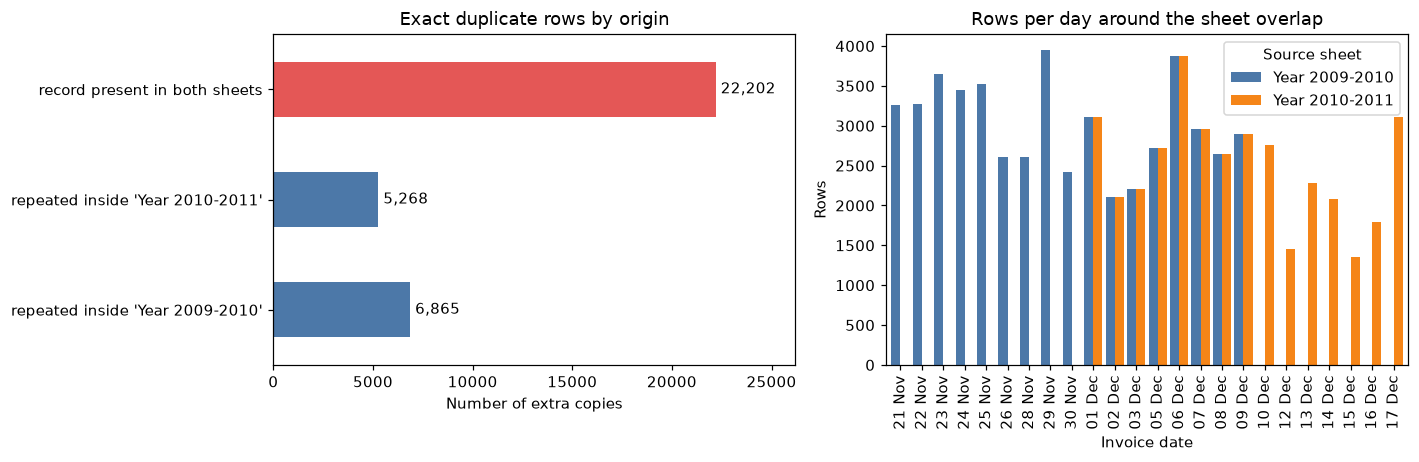

In [10]:
# Diagnostic chart 1: where do the duplicates come from?
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

dup_breakdown.plot(kind="barh", ax=axes[0], color=["#4C78A8", "#4C78A8", "#E45756"])
axes[0].set_title("Exact duplicate rows by origin")
axes[0].set_xlabel("Number of extra copies")
for i, v in enumerate(dup_breakdown.values):
    axes[0].text(v, i, f" {v:,}", va="center")
axes[0].set_xlim(0, dup_breakdown.max() * 1.18)

lo, hi = overlap_start.normalize() - pd.DateOffset(days=10), overlap_end.normalize() + pd.DateOffset(days=10)
window = df[(df["invoice_date"] >= lo) & (df["invoice_date"] < hi)]
daily = (window.groupby([window["invoice_date"].dt.normalize(), "source_sheet"], observed=True)
               .size().unstack(fill_value=0))
daily.plot(kind="bar", ax=axes[1], width=0.85, color=["#4C78A8", "#F58518"])
axes[1].set_xticklabels([d.strftime("%d %b") for d in daily.index], rotation=90)
axes[1].set_title("Rows per day around the sheet overlap")
axes[1].set_xlabel("Invoice date")
axes[1].set_ylabel("Rows")
axes[1].legend(title="Source sheet")

plt.tight_layout()
plt.show()

In [11]:
# What do exact duplicates look like? (a few examples, grouped so copies sit together)
dup_rows = df[df.duplicated(subset=ORIG_COLS, keep=False)].sort_values(["invoice", "stock_code", "invoice_date"])
display(dup_rows[ORIG_COLS + ["source_sheet"]].head(8))

print("Invoices containing at least one exact-duplicate line:", dup_rows["invoice"].nunique())

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,source_sheet
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,Year 2009-2010
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,Year 2009-2010
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010


Invoices containing at least one exact-duplicate line: 5391


**Decision for exact duplicates: remove all extra copies (keep the first occurrence).**

- *Cross-sheet records* are clearly an artefact of how the workbook was split: the first sheet runs a few days into December 2010 and the second sheet starts at 1 December 2010, so those days appear twice. Keeping them would **double-count sales** for those days, which directly distorts the best-seller ranking and the weekly forecast.
- *Repeats inside one sheet* are less certain. A shop can legitimately scan the same product twice, and no row ID lets us prove otherwise. However, rows that match on invoice, product, quantity, price, customer **and the same minute** are far more likely to be accidental double entries than genuine separate lines, and a genuine repeat would normally appear as one line with a larger quantity. We therefore remove them as well, and **measure the revenue impact below** so the effect of this judgement is visible. This remains a stated limitation.

In [12]:
# Step 2: hidden duplicates. Normalise trivial formatting differences, then recount.
df["stock_code"] = df["stock_code"].str.strip().str.upper()
df["description"] = df["description"].str.strip().str.replace(r"\s+", " ", regex=True)

total_dups_after_norm = int(df.duplicated(subset=ORIG_COLS).sum())
print(f"Exact duplicates before text normalisation: {total_dups:,}")
print(f"Exact duplicates after  text normalisation: {total_dups_after_norm:,}")
print(f"Hidden duplicates revealed by normalisation: {total_dups_after_norm - total_dups:,}")

raw_desc = raw["Description"].dropna().astype(str)
raw_codes = raw["StockCode"].astype(str)
print(f"\nDescriptions with leading/trailing spaces in the raw data: {int((raw_desc != raw_desc.str.strip()).sum()):,}")
print(f"Distinct stock codes lost by trimming/upper-casing (same product written two ways): {raw_codes.nunique() - raw_codes.str.strip().str.upper().nunique():,}")

Exact duplicates before text normalisation: 34,335
Exact duplicates after  text normalisation: 34,335
Hidden duplicates revealed by normalisation: 0



Descriptions with leading/trailing spaces in the raw data: 213,035


Distinct stock codes lost by trimming/upper-casing (same product written two ways): 174


Text normalisation (strip spaces, collapse repeated spaces, upper-case stock codes) is safe here: `85123a` and `85123A` are the same product, and padded spaces carry no meaning. The recount above shows whether this exposes any further exact duplicates.

In [13]:
# Step 3: near-duplicates = identical on everything except the description text.
# Evaluated after exact duplicates are removed, so we only look at what is left.
deduped = df.drop_duplicates(subset=ORIG_COLS, keep="first")
KEY_NO_DESC = [c for c in ORIG_COLS if c != "description"]
near_mask = deduped.duplicated(subset=KEY_NO_DESC, keep=False)
print("Rows that match another row on all fields except description:", int(near_mask.sum()))
display(deduped.loc[near_mask, ORIG_COLS].sort_values(["invoice", "stock_code"]).head(12))

Rows that match another row on all fields except description: 4


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
724585,554084,23298,"BUNTING , SPOTTY",3,2011-05-22 11:52:00,4.95,12909,United Kingdom
724605,554084,23298,SPOTTY BUNTING,3,2011-05-22 11:52:00,4.95,12909,United Kingdom
977829,575335,23203,JUMBO BAG DOILEY PATTERNS,300,2011-11-09 13:56:00,1.79,12931,United Kingdom
977832,575335,23203,JUMBO BAG VINTAGE DOILY,300,2011-11-09 13:56:00,1.79,12931,United Kingdom


**Decision for near-duplicates: flag and keep (do not delete).** These rows agree on invoice, product code, quantity, timestamp, price and customer, and differ only in how the product is described. They may be one line entered twice with a text variant, but they could also be two distinct lines on the same invoice. Because the evidence is weaker than for exact duplicates and the count is tiny, deleting them would be a guess. We add an `is_near_duplicate` flag instead so later members can test how sensitive their results are.

In [14]:
# Apply the fixes
n_before = len(df)
df["line_total"] = df["quantity"] * df["price"]
removed = df[df.duplicated(subset=ORIG_COLS, keep="first")]

clean = df.drop_duplicates(subset=ORIG_COLS, keep="first").reset_index(drop=True)
clean["is_near_duplicate"] = clean.duplicated(subset=KEY_NO_DESC, keep=False)

# Revenue impact of what was removed (line total = quantity x price)
impact = pd.DataFrame({
    "rows": [n_before, len(clean), len(removed)],
    "net_line_total": [df["line_total"].sum(), clean["line_total"].sum(), removed["line_total"].sum()],
}, index=["before", "after", "removed"])
impact["share_of_before"] = impact["net_line_total"] / impact.loc["before", "net_line_total"]
display(impact)

print(f"Removed {len(removed):,} rows ({len(removed) / n_before:.2%}), which carried {removed['line_total'].sum() / df['line_total'].sum():.2%} of net line-total value.")
print(f"Flagged near-duplicate rows kept: {int(clean['is_near_duplicate'].sum())}")

,rows,net_line_total,share_of_before
before,1067371,"19,287,250.57",1.00
after,1033036,"18,855,533.70",0.98
removed,34335,"431,716.87",0.02


Removed 34,335 rows (3.22%), which carried 2.24% of net line-total value.
Flagged near-duplicate rows kept: 4


In [15]:
# Validation: the fixes must hold, and the numbers must reconcile
assert not clean.duplicated(subset=ORIG_COLS).any(), "exact duplicates remain"
assert len(clean) == n_before - len(removed), "row counts do not reconcile"
assert str(clean["customer_id"].dtype) == "string" and str(clean["invoice"].dtype) == "string"
assert str(clean["stock_code"].dtype) == "string" and str(clean["country"].dtype) == "category"
assert pd.api.types.is_datetime64_any_dtype(clean["invoice_date"])
assert clean["customer_id"].isna().sum() == raw["Customer ID"].isna().sum() - removed["customer_id"].isna().sum()

OUT_PATH = PROCESSED_DIR / "online_retail_ii_step1.parquet"
clean.to_parquet(OUT_PATH, index=False)
print("All checks passed. Saved:", OUT_PATH.name, "| shape:", clean.shape)

All checks passed. Saved: online_retail_ii_step1.parquet | shape: (1033036, 12)


### 3.3 summary: what Member 1 changed

| Step | Issue | Action | Reason |
|---|---|---|---|
| Types | Mixed int/str identifiers, `Customer ID` as float | Converted to `string` (IDs keep missing values) | Identifiers are labels, mixed types break joins and grouping |
| Types | No cancellation indicator | Added boolean `is_cancellation` from the `C` prefix | Needed by later steps, and removes string-parsing everywhere |
| Names | Inconsistent names with spaces | `snake_case` | Safer code, consistent across the two UCI files |
| Duplicates | Records present in both sheets, and repeats inside one sheet | Dropped, keeping first occurrence | Overlapping days would double-count sales |
| Duplicates | Spacing/case variants | Normalised `stock_code` and `description`, then recounted | Checks for duplicates hidden by formatting. The recount found none extra, but normalisation still merges the same product written two different ways (e.g. `85123a` vs `85123A`), which matters for best-seller counts |
| Duplicates | Same line, different description text | Flagged (`is_near_duplicate`), kept | Evidence is too weak to delete |

**Handed to the next steps (found while profiling, not fixed here):** the counts below are the starting point for missing values, outliers and invalid values.

In [16]:
handoff = pd.Series({
    "missing customer_id": int(clean["customer_id"].isna().sum()),
    "missing description": int(clean["description"].isna().sum()),
    "cancellation rows (invoice starts with C)": int(clean["is_cancellation"].sum()),
    "quantity <= 0 on non-cancellation rows": int(((clean["quantity"] <= 0) & ~clean["is_cancellation"]).sum()),
    "price <= 0": int((clean["price"] <= 0).sum()),
    "stock codes with no digit (POST, DOT, M, BANK CHARGES ...)": int((~clean["stock_code"].str.contains(r"\d", na=False)).sum()),
    "country = 'Unspecified' or 'European Community'": int(clean["country"].isin(["Unspecified", "European Community"]).sum()),
    "stock codes with more than one description": int((clean.groupby("stock_code")["description"].nunique() > 1).sum()),
})
display(handoff.rename("rows / codes").to_frame())
print("Quantity range:", clean["quantity"].min(), "to", clean["quantity"].max(), "| Price range:", clean["price"].min(), "to", clean["price"].max())

,rows / codes
missing customer_id,235151
missing description,4275
cancellation rows (invoice starts with C),19104
quantity <= 0 on non-cancellation rows,3393
price <= 0,6019
"stock codes with no digit (POST, DOT, M, BANK CHARGES ...)",5472
country = 'Unspecified' or 'European Community',813
stock codes with more than one description,1190


Quantity range: -80995 to 80995 | Price range: -53594.36 to 38970.0


### 3.4 Missing values _(TODO: next member)_
_Where and how much is missing, how it is handled (drop / impute / flag) and why. Start from the table above (`customer_id`, `description`)._

### 3.5 Outliers _(TODO)_
_Detection method (IQR / z-score / boxplot), and whether values are kept, capped or removed, with reasons. Quantity and price have extreme values at both ends._

### 3.6 Other quality issues _(TODO)_
_Invalid values (negative or zero quantity/price, non-product stock codes), inconsistent formats and categories (country labels, description variants per stock code), and cancellations._

## 4. Exploratory (diagnostic) charts
_At least 2 labelled charts in total. Chart 1 (duplicate origins and sheet overlap) is already in section 3.3. Add missing-value and outlier charts here._

## 5. PII and bias risks _(TODO)_
_Sensitive or identifying fields (`customer_id`), sampling bias (single UK retailer, mostly UK, many wholesalers, customers without an ID), unbalanced groups, and how each would be handled._

## 6. Conclusion _(TODO)_
_Whether the data is fit for the scenario and which limitations remain._